# 1 · Reproducing the results

This notebook has two parts.

**Part A (computed live in this notebook)** downloads the two released checkpoints from the Hugging Face Hub and
re-runs the full evaluation protocol on the 360 held-out NEU-DET images.

**Part B (read from `results/`)** builds the paper tables from the stored evaluation of all 74 training runs
(5 seeds for the main models). Those runs take about 1 GPU-hour each; notebook 3 shows how to re-run any of them.

Every cell output below was produced by executing this notebook from top to bottom.

In [1]:
import json, os, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                                   # all paths below are relative to the repository root
from defect_aware_mae import data, evaluate, hub, report
from defect_aware_mae.data import CLASSES, load_split
from defect_aware_mae.models import embed, load_encoder
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
print("repo:", ROOT.name, "| device:", DEVICE, "| torch", torch.__version__)

repo: defect-aware-MAE | device: cuda | torch 2.9.1+cu128


## Data

`scripts/prepare_data.py` unpacks NEU-DET and builds the preprocessed arrays (CLAHE, resize to 224×224). The md5
check confirms the inputs are byte-identical to the ones used for the released results.

In [2]:
Xtr, ytr, _ = load_split("train", verify=True); Xva, yva, _ = load_split("validation", verify=True)
print("train", Xtr.shape, "| validation", Xva.shape, "| classes", CLASSES)
print("checksums match the reference; pretraining used the train split only")

train (1440, 224, 224) | validation (360, 224, 224) | classes ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
checksums match the reference; pretraining used the train split only


## Part A · Live evaluation of the released weights

Protocol (`defect_aware_mae/evaluate.py`): frozen encoder → standardise features → cluster the held-out images.
Labels are used only to score the clusters (Hungarian-matched accuracy, NMI, ARI); the silhouette needs no labels.

In [3]:
live = {}
for name in ("defect_aware_mae", "simclr"):
    path, mode = hub.download(name)
    live[name] = evaluate.run(path, mode, device=DEVICE)
    v = live[name]["heldout_transductive"]["umap2_ward_v1cfg"]
    print(f"{name:17s} readout={mode}: acc {100*v['acc']:.2f}  NMI {v['nmi']:.3f}  ARI {v['ari']:.3f}  silhouette {v['sil']:.3f}")

defect_aware_mae  readout=mid: acc 98.33  NMI 0.963  ARI 0.961  silhouette 0.828


simclr            readout=cls: acc 97.78  NMI 0.944  ARI 0.948  silhouette 0.724


In [4]:
# live numbers next to the numbers stored when these exact checkpoints were trained (results/runs/final_*)
stored = {"defect_aware_mae": ("final_mae_hog_energy_dec2_ep1600_s0", "mid"), "simclr": ("final_simclr_lr1.5e-4_s0", "cls")}
rows = []
for name, (tag, mode) in stored.items():
    s = report.load_run(tag, mode)
    for src, r in (("live (this notebook)", live[name]), ("stored (training machine)", s)):
        rows.append({"Checkpoint": name, "Source": src, **{m: round(f(r), 3) for m, f in report.METRICS.items()}})
pd.DataFrame(rows).set_index(["Checkpoint", "Source"]).T

Checkpoint               defect_aware_mae                                         simclr                          
Source               live (this notebook) stored (training machine) live (this notebook) stored (training machine)
Acc (UMAP+Ward)                    98.333                    98.333               97.778                    98.333
NMI                                 0.963                     0.963                0.944                     0.955
ARI                                 0.961                     0.961                0.948                     0.961
Silhouette (UMAP)                   0.828                     0.827                0.724                     0.738
Silhouette (PCA-50)                 0.489                     0.489                0.199                     0.199
Acc sweep mean                     97.655                    97.678               97.840                    97.898
Acc sweep worst                    96.000                    96.250               96.833                    97.139
Acc PCA k-means                    93.611                    93.611               94.444                    94.444
Acc 768-d k-means                  95.556                    95.556               95.000                    95.000
Acc inductive (UMAP)               95.056                    94.611               94.778                    94.611
Acc inductive (PCA)                92.778                    92.778               91.389                    91.389
kNN-20*                            96.389                    96.389               96.944                    96.944
Linear probe*                      99.722                    99.722               98.333                    98.333

Small differences between *live* and *stored* come from running the encoder on a different GPU model
(half-precision features differ in the last digits, and UMAP amplifies that). Same GPU model gives identical numbers.

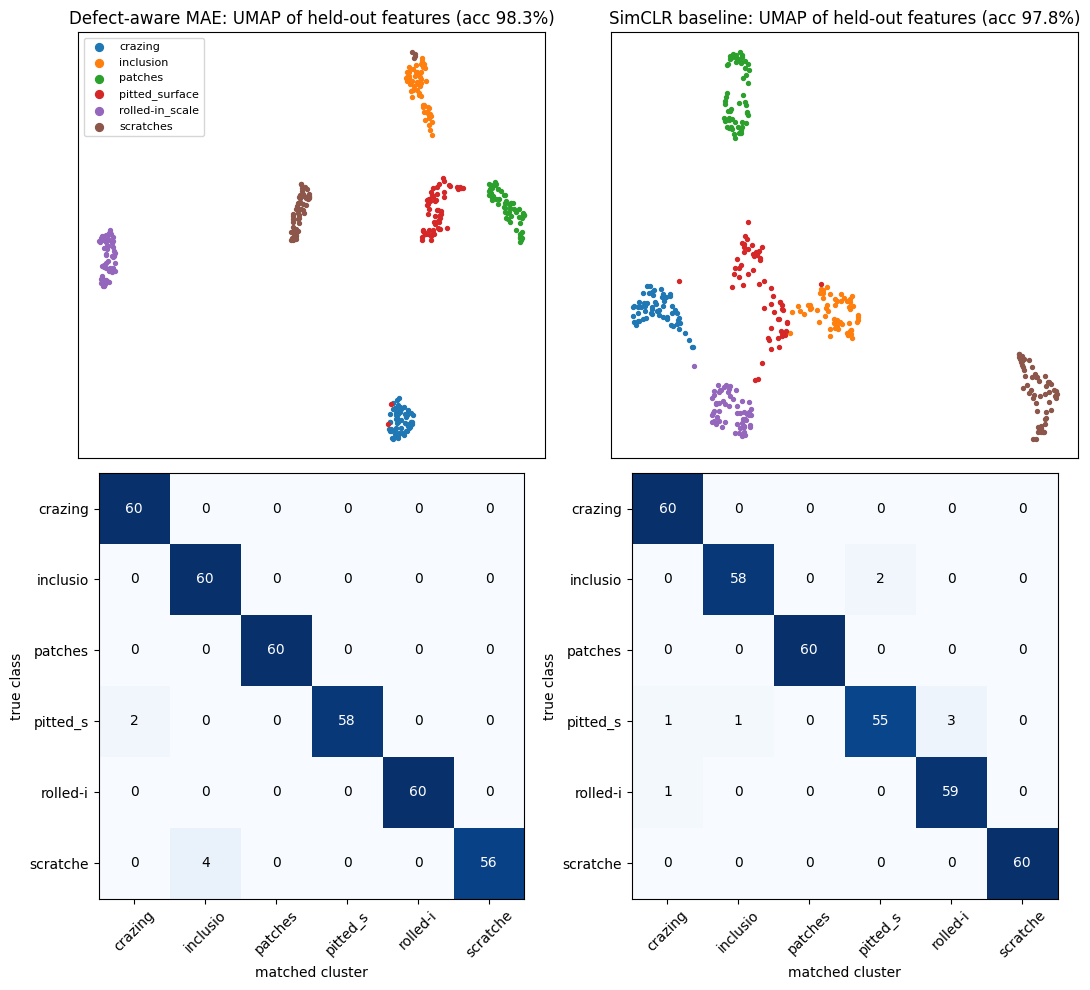

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import confusion_matrix
fig, ax = plt.subplots(2, 2, figsize=(11, 10))
for j, (name, title) in enumerate((("defect_aware_mae", "Defect-aware MAE"), ("simclr", "SimCLR baseline"))):
    path, mode = hub.download(name)
    F = embed(load_encoder(path, DEVICE), Xva, mode)
    Z = evaluate.umap2(StandardScaler().fit_transform(F))
    c = evaluate.hungarian_map(yva, AgglomerativeClustering(6).fit_predict(Z))
    for k in range(6): ax[0, j].scatter(*Z[yva == k].T, s=8, label=CLASSES[k])
    ax[0, j].set_title(f"{title}: UMAP of held-out features (acc {100*(c==yva).mean():.1f}%)"); ax[0, j].set_xticks([]); ax[0, j].set_yticks([])
    cm = confusion_matrix(yva, c, labels=range(6)); ax[1, j].imshow(cm, cmap="Blues")
    for a in range(6):
        for b in range(6): ax[1, j].text(b, a, cm[a, b], ha="center", va="center", color="w" if cm[a, b] > 30 else "k")
    ax[1, j].set_xticks(range(6)); ax[1, j].set_yticks(range(6)); ax[1, j].set_xticklabels([s[:8] for s in CLASSES], rotation=45); ax[1, j].set_yticklabels([s[:8] for s in CLASSES])
    ax[1, j].set_xlabel("matched cluster"); ax[1, j].set_ylabel("true class")
ax[0, 0].legend(fontsize=8, markerscale=2); plt.tight_layout(); plt.savefig("figures/umap_confusion.png", dpi=160); plt.show()

## Part B · Tables from the stored runs

`configs/groups.json` maps each experiment to its runs in `results/runs/<tag>/` (`eval.json`, `args.json`,
`history.json`). Values are mean ± std over seeds on the held-out split. Metrics marked `*` use labels.

In [6]:
G = json.load(open("configs/groups.json")); names = list(G)
MAE, SIM = names[0], names[1]
main = ["Acc (UMAP+Ward)", "NMI", "ARI", "Silhouette (UMAP)", "Silhouette (PCA-50)", "Acc sweep mean", "Acc sweep worst",
        "Acc PCA k-means", "Acc 768-d k-means", "Acc inductive (UMAP)", "Linear probe*"]
report.table({k: G[k] for k in (MAE, SIM)}, metrics=main).set_index("Model").T

Model,"Defect-aware MAE (final): HOG + defect masking + strong aug, 2-layer decoder, 1600 ep","SimCLR baseline (lr 1.5e-4, 800 ep)"
Seeds,5,5
Readout,mid,cls
Acc (UMAP+Ward),98.6 ± 0.2,97.8 ± 1.3
NMI,0.968 ± 0.003,0.955 ± 0.021
ARI,0.967 ± 0.004,0.951 ± 0.027
Silhouette (UMAP),0.838 ± 0.019,0.736 ± 0.019
Silhouette (PCA-50),0.503 ± 0.008,0.197 ± 0.004
Acc sweep mean,97.4 ± 0.6,97.6 ± 0.4
Acc sweep worst,95.8 ± 0.7,96.3 ± 0.8
Acc PCA k-means,95.4 ± 1.0,95.4 ± 1.1


### Significance (Welch t-test, 5 seeds each)

A = Defect-aware MAE, B = SimCLR. Accuracy differences are not significant; the silhouette difference is.

In [7]:
report.welch(G[MAE]["tags"], G[MAE]["readout"], G[SIM]["tags"], G[SIM]["readout"])

,Metric,A,B,A - B,p (Welch)
0,Acc (UMAP+Ward),98.6 ± 0.2,97.8 ± 1.3,0.778,0.294
1,NMI,0.968 ± 0.003,0.955 ± 0.021,0.013,0.285
2,ARI,0.967 ± 0.004,0.951 ± 0.027,0.016,0.301
3,Silhouette (UMAP),0.838 ± 0.019,0.736 ± 0.019,0.102,0.000
4,Silhouette (PCA-50),0.503 ± 0.008,0.197 ± 0.004,0.306,0.000
5,Acc sweep mean,97.4 ± 0.6,97.6 ± 0.4,-0.190,0.603
6,Acc sweep worst,95.8 ± 0.7,96.3 ± 0.8,-0.539,0.329
7,Acc PCA k-means,95.4 ± 1.0,95.4 ± 1.1,-0.056,0.941
8,Acc 768-d k-means,96.0 ± 0.3,95.8 ± 1.2,0.167,0.805
9,Acc inductive (UMAP),89.4 ± 4.2,95.0 ± 1.1,-5.544,0.055


### Design ablations (multi-seed)

In [8]:
cols = ["Acc (UMAP+Ward)", "Silhouette (UMAP)", "Acc sweep mean", "Acc sweep worst", "Acc PCA k-means", "Acc inductive (UMAP)"]
report.table({k: v for k, v in G.items() if not k.startswith("Ablation")}, metrics=cols)

,Model,Seeds,Readout,Acc (UMAP+Ward),Silhouette (UMAP),Acc sweep mean,Acc sweep worst,Acc PCA k-means,Acc inductive (UMAP)
0,"Defect-aware MAE (final): HOG + defect masking + strong aug, 2-layer decoder, 1600 ep",5,mid,98.6 ± 0.2,0.838 ± 0.019,97.4 ± 0.6,95.8 ± 0.7,95.4 ± 1.0,89.4 ± 4.2
1,"SimCLR baseline (lr 1.5e-4, 800 ep)",5,cls,97.8 ± 1.3,0.736 ± 0.019,97.6 ± 0.4,96.3 ± 0.8,95.4 ± 1.1,95.0 ± 1.1
2,"MAE: 1-layer decoder, 800 ep",5,mid,98.0 ± 0.5,0.835 ± 0.019,97.4 ± 0.3,96.3 ± 0.7,94.4 ± 0.9,95.3 ± 0.3
3,"MAE: 1-layer decoder, 1600 ep",5,mid,96.6 ± 0.9,0.834 ± 0.021,96.8 ± 1.3,95.4 ± 1.9,95.1 ± 1.1,92.0 ± 2.3
4,"MAE: 2-layer decoder, 800 ep",3,mid,97.9 ± 0.3,0.855 ± 0.007,97.2 ± 0.2,95.5 ± 0.4,94.4 ± 0.7,95.2 ± 0.8
5,"MAE: 4-layer decoder, 800 ep (HOG + defect masking + strong aug)",5,mid,96.9 ± 1.8,0.849 ± 0.011,96.8 ± 1.0,95.5 ± 0.8,93.2 ± 0.4,92.4 ± 4.2
6,"MAE: 8-layer decoder, 800 ep",3,mid,97.0 ± 1.4,0.853 ± 0.008,96.8 ± 0.4,95.3 ± 0.4,94.4 ± 0.3,94.3 ± 1.5
7,MAE: mask ratio 0.60,3,mid,97.6 ± 1.1,0.856 ± 0.004,96.9 ± 0.8,95.3 ± 0.3,94.6 ± 0.9,92.6 ± 3.5
8,MAE: mask ratio 0.85,3,mid,97.2 ± 1.4,0.824 ± 0.026,97.0 ± 0.8,95.2 ± 1.2,92.1 ± 1.5,88.3 ± 7.5
9,"MAE: HOG + EMA-teacher target, 4-layer decoder, 1600 ep",5,mid,96.7 ± 1.4,0.846 ± 0.023,97.1 ± 1.0,96.3 ± 0.9,92.9 ± 1.9,92.4 ± 1.5


### Component ablation (single seed)

A1–A4 share one learning rate (5e-4) and isolate the target and the masking. Single-seed rows are indicative only:
seed-to-seed spread is 1–2 points.

In [9]:
report.table({k: v for k, v in G.items() if k.startswith("Ablation")}, metrics=cols)

,Model,Seeds,Readout,Acc (UMAP+Ward),Silhouette (UMAP),Acc sweep mean,Acc sweep worst,Acc PCA k-means,Acc inductive (UMAP)
0,"Ablation A1 (1 seed, lr 5e-4): pixel target, random masking",1,mid,76.9,0.530,71.9,69.9,52.5,60.7
1,"Ablation A2 (1 seed, lr 5e-4): pixel target, defect-aware masking",1,mid,71.9,0.624,73.5,71.6,51.9,61.3
2,"Ablation A3 (1 seed, lr 5e-4): HOG target, random masking",1,mid,92.8,0.802,93.9,92.7,92.5,79.8
3,"Ablation A4 (1 seed, lr 5e-4): HOG target, defect-aware masking",1,mid,96.4,0.824,96.3,95.5,95.3,88.8
4,"Ablation B1 (1 seed, lr 1.5e-4): pixel target, random masking",1,mid,73.9,0.584,84.3,78.8,70.8,65.1
5,"Ablation B2 (1 seed, lr 1.5e-4): HOG target, defect-aware masking",1,mid,96.7,0.817,95.9,94.5,95.0,91.9


### Effect of the readout

The same runs read out three ways. The MAE needs the intermediate-layer (`mid`) or mean-pooled readout; its CLS
token is a weak feature. SimCLR is best with CLS, which its loss trains directly.

In [10]:
pd.concat([report.table({k: G[k] for k in (MAE, SIM)}, readout=r, metrics=cols) for r in ("cls", "mean", "mid")]).sort_values("Model")

,Model,Seeds,Readout,Acc (UMAP+Ward),Silhouette (UMAP),Acc sweep mean,Acc sweep worst,Acc PCA k-means,Acc inductive (UMAP)
0,"Defect-aware MAE (final): HOG + defect masking + strong aug, 2-layer decoder, 1600 ep",5,cls,92.8 ± 4.3,0.786 ± 0.048,93.2 ± 2.0,91.5 ± 2.7,90.2 ± 5.7,76.8 ± 2.7
0,"Defect-aware MAE (final): HOG + defect masking + strong aug, 2-layer decoder, 1600 ep",5,mean,97.7 ± 1.0,0.842 ± 0.025,97.2 ± 0.7,95.9 ± 0.8,95.0 ± 0.8,91.2 ± 3.1
0,"Defect-aware MAE (final): HOG + defect masking + strong aug, 2-layer decoder, 1600 ep",5,mid,98.6 ± 0.2,0.838 ± 0.019,97.4 ± 0.6,95.8 ± 0.7,95.4 ± 1.0,89.4 ± 4.2
1,"SimCLR baseline (lr 1.5e-4, 800 ep)",5,cls,97.8 ± 1.3,0.736 ± 0.019,97.6 ± 0.4,96.3 ± 0.8,95.4 ± 1.1,95.0 ± 1.1
1,"SimCLR baseline (lr 1.5e-4, 800 ep)",5,mean,80.9 ± 2.1,0.606 ± 0.022,81.3 ± 4.1,77.0 ± 5.1,65.7 ± 8.4,79.6 ± 7.2
1,"SimCLR baseline (lr 1.5e-4, 800 ep)",5,mid,86.9 ± 2.6,0.673 ± 0.041,86.6 ± 2.6,84.0 ± 3.1,78.6 ± 3.1,86.0 ± 3.2


### References: raw pixels, random encoder, and the earlier box-supervised model (v1)

These come from the pilot study (`results/pilot/`, CLS readout). `v1_joint_mae_det` is the earlier model whose
encoder was trained jointly with a detection branch using bounding boxes, so it is **not** unsupervised.
The pilot `mae` / `simclr` / `dmae` rows are 200-epoch runs with a learning rate that was too low; they are kept
for completeness and superseded by the tables above.

In [11]:
rows = []
for f in sorted(Path("results/pilot").glob("*.json")):
    R = json.load(open(f))
    if "heldout_transductive" not in R: continue
    rows.append({"Model": f.stem, **{m: round(fn(R), 3) for m, fn in report.METRICS.items() if m in cols + ["Linear probe*"]}})
pd.DataFrame(rows)

,Model,Acc (UMAP+Ward),Silhouette (UMAP),Acc sweep mean,Acc sweep worst,Acc PCA k-means,Acc inductive (UMAP),Linear probe*
0,dmae_s0,41.944,0.387,48.634,44.694,42.778,42.611,89.722
1,dmae_s1,61.389,0.504,71.176,66.500,53.889,60.778,89.167
2,dmae_s2,79.444,0.684,77.537,71.083,55.556,71.167,88.056
3,mae_s0,68.889,0.448,62.650,57.889,48.611,50.667,88.611
4,mae_s1,55.833,0.479,55.620,51.056,47.500,51.111,86.667
5,mae_s2,69.444,0.455,69.970,66.639,54.722,49.944,88.333
6,random0,51.111,0.373,58.294,49.917,48.056,47.556,80.000
7,raw,51.667,0.432,51.808,48.778,56.111,51.833,37.778
8,simclr_s0,93.889,0.744,93.481,92.694,90.278,91.944,98.889
9,simclr_s1,91.667,0.775,91.481,91.056,88.889,89.667,97.778


### Training curves (5 seeds)

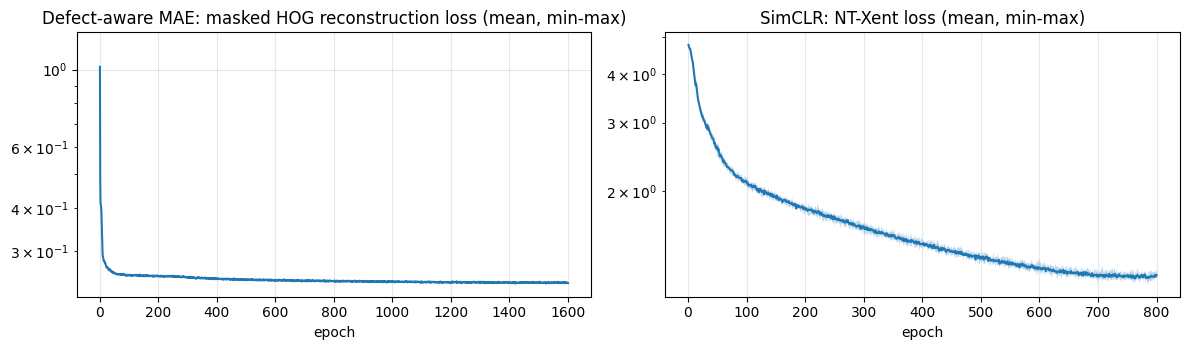

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, (g, key, t) in zip(ax, ((MAE, "rec", "Defect-aware MAE: masked HOG reconstruction loss"), (SIM, "nce", "SimCLR: NT-Xent loss"))):
    H = np.array([[e[key] for e in json.load(open(f"results/runs/{tag}/history.json"))] for tag in G[g]["tags"]]); x = np.arange(1, H.shape[1] + 1)
    a.plot(x, H.mean(0)); a.fill_between(x, H.min(0), H.max(0), alpha=.3); a.set_yscale("log"); a.set_xlabel("epoch"); a.set_title(t + " (mean, min-max)"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/training_curves.png", dpi=160); plt.show()

## Reading these results

- **Accuracy:** the Defect-aware MAE matches the tuned contrastive baseline (not a significant difference) with much
  lower variance across seeds.
- **Cluster quality:** its silhouette is clearly higher, in UMAP space and in PCA space.
- **Inductive setting:** SimCLR is better when the clustering is fitted on training images and applied to unseen
  ones; the 1-layer-decoder MAE variant closes that gap.
- **Caveats:** variants were compared on this same held-out split (about 70 explored; no separate development
  split), the baseline received less tuning than the MAE, and everything is on one dataset with K = 6 given.